数据验收与清洗
分析对象：数据质量验收 + 清洗到 DWD 明细层
    完整性：字段缺失率（区分结构性缺失与质量缺失）
    规范性：CALL_TYPE / POLYLINE / 坐标范围
    唯一性：TRIP_ID 完全重复
    一致性：相邻 GPS 点的时间间隔（标称 15 秒）
    主键  ：TRIP_ID 能否唯一标识一趟行程
    清洗  ：空轨迹 / 重复 / 越界，逐步记录 -> dwd
    稀疏性：同一辆车相邻两趟行程的间隔（类比信令间隔 gap）

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FixedFormatter, PercentFormatter

import taxi_common as tc

SCRIPT = "数据验收与清洗"
tc.AUTHOR = "高帅龙 2428324009"
SOURCE = tc.source_line(SCRIPT)
tc.apply_theme()

raw = tc.load_raw()
N0 = len(raw)

In [26]:
# 完整性
print("完整性：字段缺失率\n")
miss = pd.DataFrame({
    "字段": ["TRIP_ID", "CALL_TYPE", "ORIGIN_CALL", "ORIGIN_STAND", "TAXI_ID",
            "TIMESTAMP", "DAY_TYPE", "MISSING_DATA", "POLYLINE"],
})
miss["缺失数"] = miss["字段"].map(lambda c: int(raw[c].isna().sum()))
miss["缺失率"] = miss["缺失数"] / N0
# 结构性缺失判定：缺失是否能用 CALL_TYPE 解释
miss["口径"] = miss["字段"].map({
    "ORIGIN_CALL": "结构性缺失：仅 CALL_TYPE=A 有值",
    "ORIGIN_STAND": "结构性缺失：仅 CALL_TYPE=B/C 有值",
}).fillna("应完整")
print(miss.to_string(index=False))
# 验证：A 型的 ORIGIN_CALL 是否齐全、B/C 的 ORIGIN_STAND 情况
a_call_miss = raw.loc[raw["CALL_TYPE"] == "A", "ORIGIN_CALL"].isna().sum()
bc_stand_miss = raw.loc[raw["CALL_TYPE"].isin(["B", "C"]), "ORIGIN_STAND"].isna().sum()
print(f"\nA 型 {len(raw[raw.CALL_TYPE=='A']):,} 趟中 ORIGIN_CALL 仍缺 {a_call_miss}；"
      f"B/C 型 ORIGIN_STAND 缺 {bc_stand_miss}（C 型可无站台）")

完整性：字段缺失率

          字段   缺失数     缺失率                       口径
     TRIP_ID     0 0.00000                      应完整
   CALL_TYPE     0 0.00000                      应完整
 ORIGIN_CALL 79038 0.79038   结构性缺失：仅 CALL_TYPE=A 有值
ORIGIN_STAND 50689 0.50689 结构性缺失：仅 CALL_TYPE=B/C 有值
     TAXI_ID     0 0.00000                      应完整
   TIMESTAMP     0 0.00000                      应完整
    DAY_TYPE     0 0.00000                      应完整
MISSING_DATA     0 0.00000                      应完整
    POLYLINE     0 0.00000                      应完整

A 型 20,962 趟中 ORIGIN_CALL 仍缺 0；B/C 型 ORIGIN_STAND 缺 29727（C 型可无站台）


In [13]:
# 规范性
print("规范性\n")
print("CALL_TYPE 取值：", raw["CALL_TYPE"].value_counts().to_dict())
print("DAY_TYPE 取值 ：", raw["DAY_TYPE"].value_counts().to_dict())
print("MISSING_DATA  ：", raw["MISSING_DATA"].value_counts().to_dict())

# 波尔图都市区合理框（含机场/港口），越界 = 坐标异常
LNG_OK, LAT_OK = (-9.0, -8.0), (40.8, 41.6)
oob = ~(raw["lng0"].between(*LNG_OK) & raw["lat0"].between(*LAT_OK))
print(f"首点越出都市区框的行程：{oob.sum()} 趟")

规范性

CALL_TYPE 取值： {'B': 49922, 'C': 29116, 'A': 20962}
DAY_TYPE 取值 ： {'A': 100000}
MISSING_DATA  ： {False: 100000}
首点越出都市区框的行程：382 趟


In [27]:
# 一致性：GPS 点间隔
print("一致性：GPS 点间距离（时间间隔标称 15s）\n")
# 抽样 5000 趟，计算相邻点的 haversine 距离（米），看 15 秒内能移动多远
def hav_m(poly):
    arr = np.asarray(poly, dtype=float)
    if len(arr) < 2:
        return np.array([])
    lng, lat = np.radians(arr[:, 0]), np.radians(arr[:, 1])
    dl = lng[1:] - lng[:-1]
    dp = lat[1:] - lat[:-1]
    a = np.sin(dp / 2) ** 2 + np.cos(lat[:-1]) * np.cos(lat[1:]) * np.sin(dl / 2) ** 2
    return 6371000 * 2 * np.arcsin(np.sqrt(a))

valid_trips = raw[raw["n_pts"] >= 2]
sample = valid_trips.sample(
    min(5000, len(valid_trips)),
    random_state=0
)
seg_d = np.concatenate([hav_m(p) for p in sample["poly"]])
# 15 秒内移动超过 ~420m（=100km/h）属异常跳点
JUMP_M = 420
print(f"相邻点距离中位 {np.median(seg_d):.0f} m，P99 {np.quantile(seg_d,.99):.0f} m；"
      f"跳点(>{JUMP_M}m)占 {np.mean(seg_d > JUMP_M):.3%}")

一致性：GPS 点间距离（时间间隔标称 15s）

相邻点距离中位 91 m，P99 523 m；跳点(>420m)占 3.111%


In [28]:

# ---------------------------------------------------------------- 唯一性
print("\n" + "=" * 60, "\n唯一性：重复记录检查\n", "=" * 60)

# 1. 检查 TRIP_ID 重复情况
dup_trip = raw["TRIP_ID"].duplicated(keep=False)
print(
    f"TRIP_ID 重复涉及 {dup_trip.sum()} 行，"
    f"唯一值数量为 {raw['TRIP_ID'].nunique():,}"
)

# 2. 检查所有字段完全相同的重复记录
full_dup = raw.duplicated(keep="first")
print(f"整行完全重复（所有字段相同）：{full_dup.sum()} 行")

# 3. 检查核心四字段组合重复记录
key_cols = ["TRIP_ID", "TAXI_ID", "TIMESTAMP", "POLYLINE"]
key_dup = raw.duplicated(subset=key_cols, keep="first")
print(f"核心四字段组合重复：{key_dup.sum()} 行")


唯一性：TRIP_ID 重复

TRIP_ID 完全重复涉及 16 行（99992 个唯一值）
四要素完全重复（应剔除）：0 行


In [29]:
# 主键验证
print("主键验证：TRIP_ID 唯一率 = "
      f"{raw['TRIP_ID'].nunique() / N0:.4%}（接近 1，可作主键，重复行清洗后即唯一）")

主键验证：TRIP_ID 唯一率 = 99.9920%（接近 1，可作主键，重复行清洗后即唯一）


In [16]:
# 执行清洗
print("执行清洗，逐步记录\n")
steps = []
work = raw.copy()
def log_step(name, before, after):
    steps.append({"步骤": name, "剔除行数": before - after,
                  "剔除占比": (before - after) / N0, "保留行数": after})
    print(f"{name:16s} 剔除 {before - after:5d}，保留 {after:,}")

# 1 空轨迹
b = len(work); work = work[work["n_pts"] > 0]
log_step("空轨迹", b, len(work))
# 2 核心四字段组合重复
b = len(work)
work = work[
    ~work.duplicated(
        subset=["TRIP_ID", "TAXI_ID", "TIMESTAMP", "POLYLINE"],
        keep="first"
    )
]
log_step("四字段组合重复", b, len(work))
# 3 首点越界
b = len(work)
inbox = work["lng0"].between(*LNG_OK) & work["lat0"].between(*LAT_OK)
work = work[inbox]
log_step("首点越界", b, len(work))

steps_df = pd.DataFrame(steps)
total_removed = N0 - len(work)
print(f"\n合计剔除 {total_removed} 趟（{total_removed/N0:.2%}），"
      f"清洗后 DWD：{len(work):,} 趟")
work.to_pickle(tc.CACHE_DIR / "dwd.pkl")
steps_df.to_pickle(tc.CACHE_DIR / "clean_steps.pkl")

执行清洗，逐步记录

空轨迹              剔除   367，保留 99,633
完全重复             剔除     0，保留 99,633
首点越界             剔除    15，保留 99,618

合计剔除 382 趟（0.38%），清洗后 DWD：99,618 趟


In [18]:
# 稀疏性：相邻趟次间隔
print("稀疏性：同一辆车相邻两趟行程的间隔\n")
gap = (work.sort_values("ts_local").groupby("TAXI_ID")["ts_local"]
       .diff().dt.total_seconds().div(60).dropna())
gap = gap[gap >= 0]
print(f"间隔（分钟）中位 {gap.median():.1f}，P90 {gap.quantile(.9):.1f}，"
      f"P99 {gap.quantile(.99):.1f}")
print(f"间隔 ≥ 30 分钟的趟次占 {np.mean(gap >= 30):.1%}（候客/空驶间隙，D6 会用于驻留）")

稀疏性：同一辆车相邻两趟行程的间隔

间隔（分钟）中位 60.7，P90 189.8，P99 1042.4
间隔 ≥ 30 分钟的趟次占 80.0%（候客/空驶间隙，D6 会用于驻留）


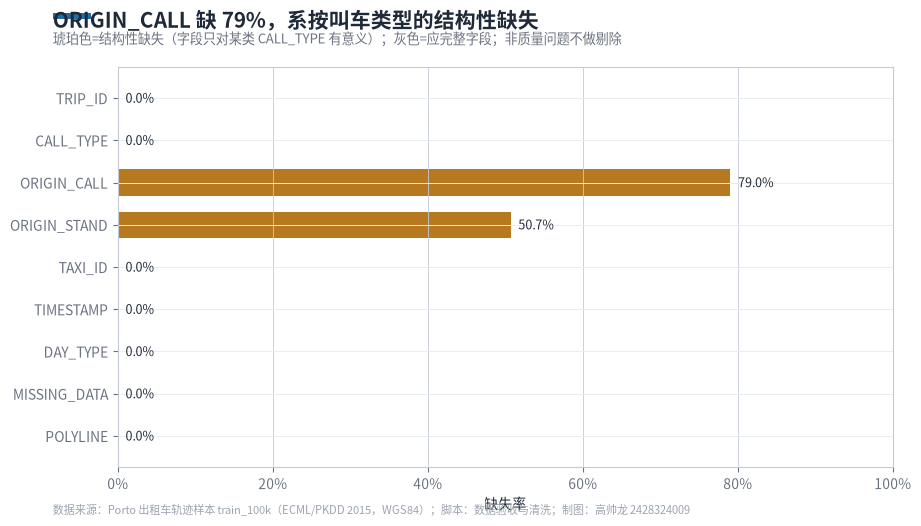

In [22]:
# 字段缺失率
fig, ax = plt.subplots(figsize=(10, 5.2), dpi=100)
colors = [tc.AMBER if "结构性" in k else tc.GRAY for k in miss["口径"]]
bars = ax.barh(miss["字段"], miss["缺失率"], color=colors, height=0.62)
ax.set_xlim(0, 1.0)
ax.xaxis.set_major_formatter(PercentFormatter(1))
for i, r in miss.iterrows():
    ax.text(r["缺失率"] + 0.01, i, f"{r['缺失率']:.1%}",
            va="center", fontsize=9, color=tc.INK)
ax.set_xlabel("缺失率")
ax.invert_yaxis()
ax.grid(axis="x", color=tc.GRAY, lw=0.6)
tc.finish(
    fig,
    f"ORIGIN_CALL 缺 {miss.loc[miss.字段=='ORIGIN_CALL','缺失率'].iloc[0]:.0%}，"
    "系按叫车类型的结构性缺失",
    "琥珀色=结构性缺失（字段只对某类 CALL_TYPE 有意义）；灰色=应完整字段；非质量问题不做剔除",
    SOURCE, "D2_01_字段缺失率.png")
plt.show()

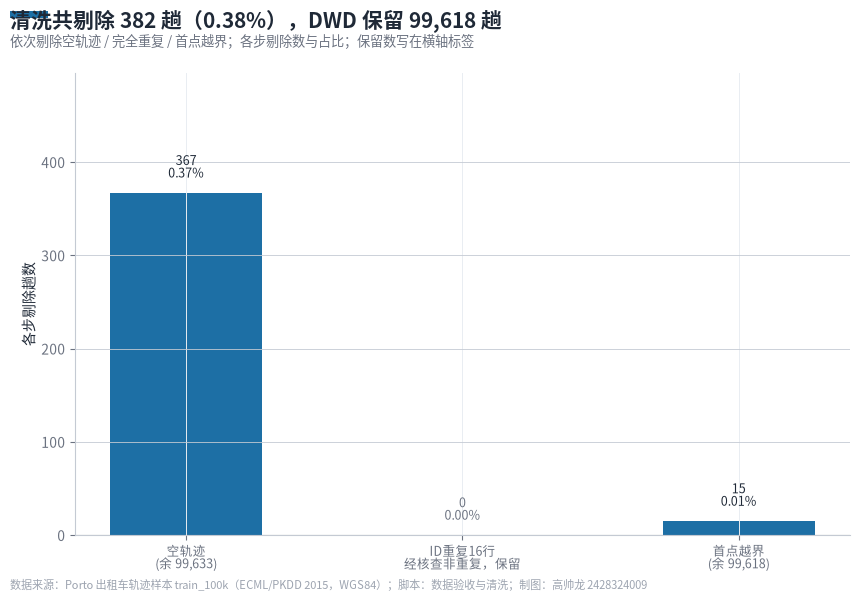

In [25]:
# 清洗剔除瀑布
fig, ax = plt.subplots(figsize=(10, 6), dpi=100)
xs = np.arange(len(steps))
bar_h = steps_df["剔除行数"].values
ax.bar(xs, bar_h, color=tc.MAIN, width=0.55)

# 标签：紧贴柱子上方，不再用 N0*0.004 那个错误偏移
pad = max(bar_h) * 0.04
for i, s in enumerate(steps):
    h = s["剔除行数"]
    if h > 0:
        ax.text(i, h + pad, f"{h}\n{s['剔除占比']:.2%}",
                ha="center", va="bottom", fontsize=9, color=tc.INK)
    else:
        ax.text(i, pad, f"{h}\n{s['剔除占比']:.2%}",
                ha="center", va="bottom", fontsize=9, color=tc.MUTED)

ax.axhline(0, color=tc.GRAY_DARK, lw=0.8)
ax.set_xticks(xs)
xlabels = [f"{s['步骤']}\n(余 {s['保留行数']:,})" for s in steps]
xlabels[1] = f"四字段组合重复\n剔除{steps[1]['剔除行数']}行"
ax.set_xticklabels(xlabels, fontsize=9)
ax.set_ylabel("各步剔除趟数")
ax.set_ylim(0, max(bar_h) * 1.35)
ax.grid(axis="y", color=tc.GRAY, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)

tc.finish(
    fig,
    f"清洗共剔除 {total_removed} 趟（{total_removed/N0:.2%}），DWD 保留 {len(work):,} 趟",
    "依次剔除空轨迹 / 完全重复 / 首点越界；各步剔除数与占比；保留数写在横轴标签",
    SOURCE, "D2_02_清洗剔除瀑布.png")
plt.show()


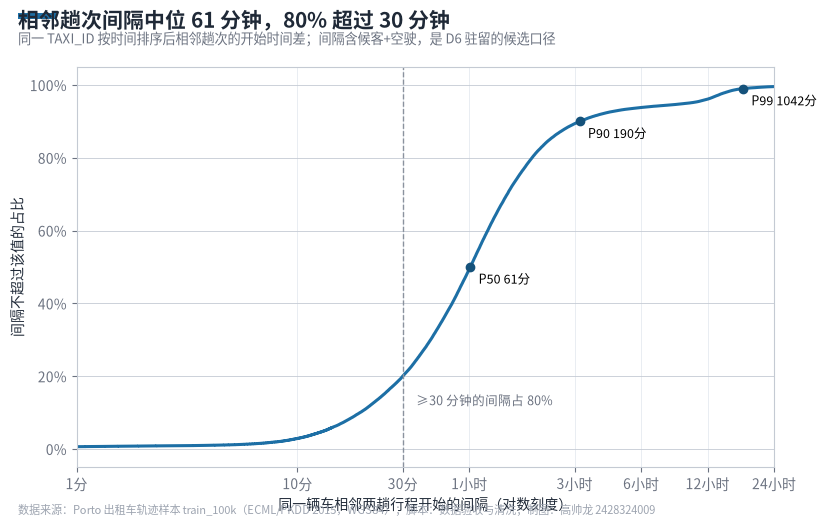


完成：图片已保存至 C:\Users\GSL\Desktop\taxi_analysis\image


In [24]:
# 相邻趟次间隔 ECDF
fig, ax = plt.subplots(figsize=(9, 5.2), dpi=100)
xs = np.sort(gap.values)
ys = np.arange(1, len(xs) + 1) / len(xs)
ax.plot(xs, ys, color=tc.MAIN, lw=2.2)
ax.set_xscale("log")
ax.set_xlim(1, 24 * 60)
ticks = [1, 10, 30, 60, 180, 360, 720, 1440]
labels = ["1分", "10分", "30分", "1小时", "3小时", "6小时", "12小时", "24小时"]
ax.xaxis.set_major_locator(FixedLocator(ticks))
ax.xaxis.set_major_formatter(FixedFormatter(labels))
ax.xaxis.set_minor_locator(FixedLocator([]))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.axvline(30, color=tc.GRAY_DARK, lw=1, ls="--")
for q in (.5, .9, .99):
    v = np.quantile(xs, q)
    ax.plot(v, q, "o", color=tc.MAIN_DARK, ms=6, zorder=3)
    ax.annotate(f"P{int(q*100)} {v:.0f}分", (v, q),
                xytext=(6, -12), textcoords="offset points", fontsize=9)
sh30 = np.mean(gap >= 30)
ax.text(30 * 1.15, 0.12, f"≥30 分钟的间隔占 {sh30:.0%}", fontsize=9, color=tc.MUTED)
ax.set_xlabel("同一辆车相邻两趟行程开始的间隔（对数刻度）")
ax.set_ylabel("间隔不超过该值的占比")
ax.grid(axis="y", color=tc.GRAY, lw=0.6)
tc.finish(
    fig,
    f"相邻趟次间隔中位 {gap.median():.0f} 分钟，{sh30:.0%} 超过 30 分钟",
    "同一 TAXI_ID 按时间排序后相邻趟次的开始时间差；间隔含候客+空驶，是 D6 驻留的候选口径",
    SOURCE, "D2_03_相邻趟次间隔.png")
plt.show()
print("完成：图片已保存至", tc.IMAGE_DIR)